# KDD End-to-End: Knowledge Discovery in Grocery Baskets
**Author:** Anshita Shah · MSSE, San José State University · CMPE 255 Data Mining

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Anshi-12/data-mining-methodologies/blob/main/KDD_Grocery-Basket/KDD_Grocery_Basket.ipynb)

The **KDD process** (Fayyad, Piatetsky-Shapiro & Smyth, 1996) defines *knowledge discovery* as the non-trivial process of identifying **valid, novel, potentially useful and ultimately understandable** patterns in data. Data mining is only *one* step of it:

```
Data ──Selection──▶ Target data ──Preprocessing──▶ Preprocessed data ──Transformation──▶ Transformed data
     ──Data Mining──▶ Patterns ──Interpretation/Evaluation──▶ Knowledge
```

| Step | What is done in this project |
|---|---|
| 0. Domain understanding & goals | Retail cross-selling: which products are bought together? |
| 1. Selection | 9,835 point-of-sale baskets; choose basket-level item presence as target data |
| 2. Preprocessing | Normalise item names, de-duplicate within baskets, remove non-product noise ("shopping bags"), handle empty baskets |
| 3. Transformation | Basket → one-hot transaction matrix; rare-item reduction; **concept hierarchy** (item → department) |
| 4. Data mining | Apriori **and** FP-Growth (verified identical); association rules at item and department level |
| 5. Interpretation / Evaluation | Support, confidence, lift, leverage, conviction; Fisher exact test + Bonferroni; redundancy pruning; **hold-out validation**; knowledge consolidation |
| (Use of knowledge) | `rules.json` + a "frequently bought together" recommender app |

KDD is iterative — the notebook documents where an evaluation result sent us **back** to an earlier step.

**Dataset:** *Groceries* (Hahsler, Hornik & Reutterer, 2006; on Kaggle as "Groceries dataset for Market Basket Analysis") — one month of real POS data from a grocery outlet, 169 product categories.

In [1]:
import os, json, time, warnings
from collections import Counter
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy.stats import fisher_exact
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep"); plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_colwidth", 80)
os.makedirs("figures", exist_ok=True); os.makedirs("models", exist_ok=True)
try:
    import mlxtend
except ImportError:
    os.system("pip -q install mlxtend")
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules
LOCAL = "data/groceries.csv"
RAW = "https://raw.githubusercontent.com/Anshi-12/data-mining-methodologies/main/KDD_Grocery-Basket/data/groceries.csv"
print("mlxtend", mlxtend.__version__ if 'mlxtend' in dir() else "installed")

mlxtend 0.25.0


---
# Step 0 — Developing an understanding of the application domain
- **Domain:** a grocery outlet wants to increase basket size through product placement, bundles and "you may also like" prompts.
- **Prior knowledge:** staples (milk, bread, vegetables) appear in many baskets and will dominate naïve frequency counts — interesting knowledge must go *beyond* "people buy milk".
- **KDD goal:** discover association rules **X → Y** that are (a) statistically valid, (b) stable on unseen baskets, (c) non-obvious, and (d) actionable for merchandising.
- **Success criteria for discovered knowledge:** lift > 1 with Fisher p < 0.05 after Bonferroni correction, and lift still > 1 on a hold-out set of baskets.

---
# Step 1 — Selection
Each line in the source file is one transaction (a comma-separated list of item categories). The target data are **all baskets**, with item **presence** (not quantity/price — not recorded in this source).

In [2]:
if os.path.exists(LOCAL):
    lines = open(LOCAL, encoding="utf-8").read().splitlines()
else:
    import urllib.request
    lines = urllib.request.urlopen(RAW).read().decode("utf-8").splitlines()
raw_baskets = [l.split(",") for l in lines]
print(f"Transactions selected: {len(raw_baskets):,}")
print("First 5 baskets:"); [print("  ", b) for b in raw_baskets[:5]]

Transactions selected: 9,835
First 5 baskets:
   ['citrus fruit', 'semi-finished bread', 'margarine', 'ready soups']
   ['tropical fruit', 'yogurt', 'coffee']
   ['whole milk']
   ['pip fruit', 'yogurt', 'cream cheese ', 'meat spreads']
   ['other vegetables', 'whole milk', 'condensed milk', 'long life bakery product']


[None, None, None, None, None]

---
# Step 2 — Preprocessing (cleaning)

In [3]:
n_items_raw = sum(len(b) for b in raw_baskets)
clean = []
stats_ = Counter()
for b in raw_baskets:
    items = [i.strip().lower() for i in b if i.strip()]
    if len(items) != len(b): stats_["blank tokens removed"] += len(b) - len(items)
    uniq = list(dict.fromkeys(items))
    stats_["within-basket duplicates removed"] += len(items) - len(uniq)
    clean.append(uniq)
print(f"Raw item tokens: {n_items_raw:,}"); [print(f"  {k}: {v}") for k, v in stats_.items()]
item_freq = pd.Series(Counter(i for b in clean for i in b)).sort_values(ascending=False)
print(f"Distinct items: {len(item_freq)}")
item_freq.head(15)

Raw item tokens: 43,367
  within-basket duplicates removed: 0
Distinct items: 169


whole milk          2513
other vegetables    1903
rolls/buns          1809
soda                1715
yogurt              1372
bottled water       1087
root vegetables     1072
tropical fruit      1032
shopping bags        969
sausage              924
pastry               875
citrus fruit         814
bottled beer         792
newspapers           785
canned beer          764
dtype: int64

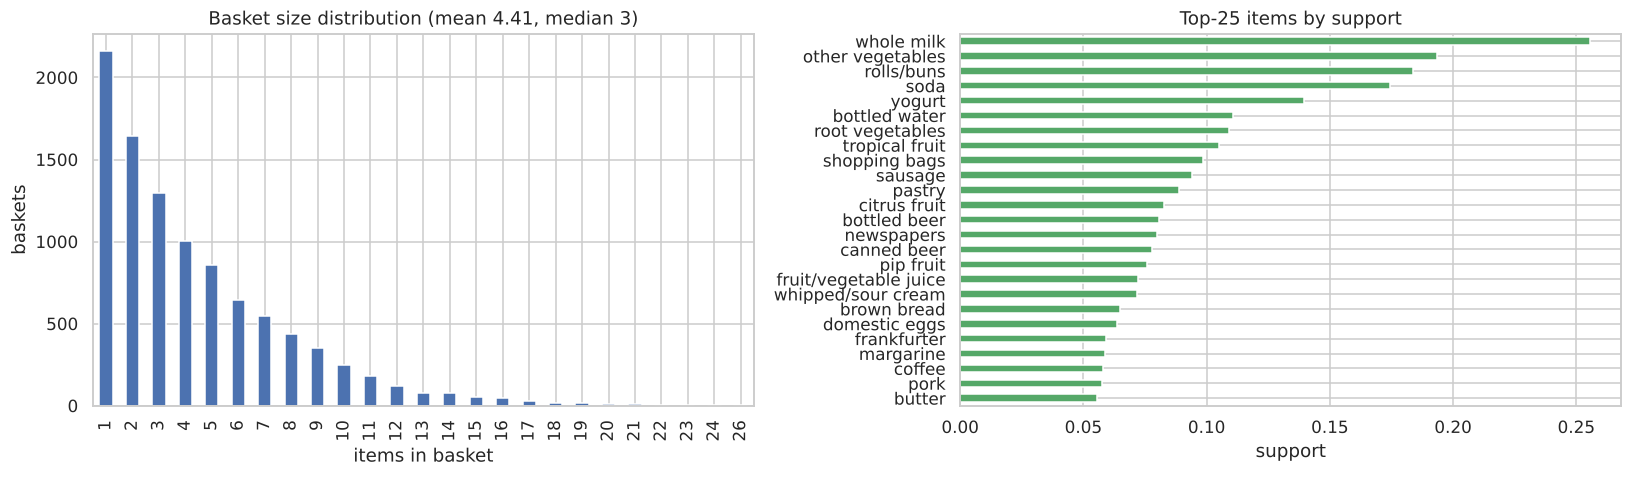

Single-item baskets: 2,159 (22.0%)


In [4]:
sizes = pd.Series([len(b) for b in clean])
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
sizes.value_counts().sort_index().head(25).plot.bar(ax=axes[0], color="#4C72B0")
axes[0].set(title=f"Basket size distribution (mean {sizes.mean():.2f}, median {sizes.median():.0f})", xlabel="items in basket", ylabel="baskets")
(item_freq / len(clean)).head(25)[::-1].plot.barh(ax=axes[1], color="#55A868")
axes[1].set(title="Top-25 items by support", xlabel="support")
plt.tight_layout(); plt.savefig("figures/01_basket_size_item_support.png"); plt.show()
print(f"Single-item baskets: {(sizes == 1).sum():,} ({(sizes == 1).mean():.1%})")

**Preprocessing decisions**
1. **"shopping bags"** is in the top-10 items but is not a product — it is a checkout artefact. Rules such as *{shopping bags} → {soda}* would be noise. **Removed** (domain-knowledge cleaning).
2. Single-item baskets contribute to item support but cannot generate rules. They are **kept** — dropping them would inflate every support value and bias the lift calculation.
3. Baskets that become empty after removing bags are dropped.

In [5]:
NOISE = {"shopping bags"}
pre = [[i for i in b if i not in NOISE] for b in clean]
pre = [b for b in pre if b]
print(f"Baskets after preprocessing: {len(pre):,}  (removed {len(clean) - len(pre)} that contained only bags)")

Baskets after preprocessing: 9,787  (removed 48 that contained only bags)


---
# Step 3 — Transformation
1. **Encoding:** list-of-items → Boolean transaction matrix (baskets × items).
2. **Reduction:** items with support < 0.5% cannot appear in any rule at our support threshold; dropping them shrinks the search space.
3. **Concept hierarchy:** map 169 categories to ~10 **departments**, enabling multi-level mining (department-level patterns are often more actionable for store layout).
4. **Hold-out split:** baskets are split 80/20 (shuffled, fixed seed) — rules are mined on the discovery set and *validated* on the hold-out set in Step 5.

In [6]:
rng = np.random.default_rng(7)
idx = rng.permutation(len(pre)); cut = int(.8 * len(pre))
disc_b = [pre[i] for i in idx[:cut]]; hold_b = [pre[i] for i in idx[cut:]]

te = TransactionEncoder()
te.fit(pre)  # vocabulary from all baskets (item names only, no statistics)
disc = pd.DataFrame(te.transform(disc_b), columns=te.columns_)
hold = pd.DataFrame(te.transform(hold_b), columns=te.columns_)
print("Discovery matrix:", disc.shape, " Hold-out matrix:", hold.shape)

support = disc.mean()
keep = support[support >= 0.005].index
print(f"Items kept after reduction (support ≥ 0.5%): {len(keep)} of {disc.shape[1]}  → density {disc[keep].values.mean():.3%}")
disc_r, hold_r = disc[keep], hold[keep]

Discovery matrix: (7829, 168)  Hold-out matrix: (1958, 168)
Items kept after reduction (support ≥ 0.5%): 119 of 168  → density 3.529%


In [7]:
DEPT_RULES = [
    ("dairy", ["milk", "yogurt", "cheese", "butter", "cream", "curd", "quark", "whipped"]),
    ("produce", ["vegetables", "fruit", "root", "onions", "herbs", "berries", "grapes", "citrus", "pip", "tropical"]),
    ("bakery", ["bread", "rolls", "buns", "pastry", "cake", "waffles", "baking", "zwieback"]),
    ("meat & fish", ["meat", "beef", "pork", "chicken", "sausage", "frankfurter", "ham", "hamburger", "fish", "turkey", "salami", "liver"]),
    ("beverages", ["water", "soda", "juice", "beer", "wine", "coffee", "tea", "liquor", "spirits", "beverages", "cocoa"]),
    ("snacks & sweets", ["chocolate", "candy", "chips", "snack", "popcorn", "nuts", "specialty bar", "ice cream", "dessert", "salty"]),
    ("frozen", ["frozen"]),
    ("pantry", ["pasta", "rice", "flour", "sugar", "oil", "vinegar", "sauce", "soup", "spread", "jam", "margarine", "mustard", "ketchup",
                "condensed", "cereals", "canned", "eggs", "spices", "salt", "honey", "pickled", "mayonnaise", "dressing", "instant food"]),
    ("household & care", ["napkins", "detergent", "cleaner", "hygiene", "dish", "toilet", "softener", "bags", "film", "foil", "candles",
                          "pet", "cat food", "dog food", "soap", "cosmetics", "shampoo", "dental", "flower", "newspapers", "light bulbs", "kitchen", "battery"]),
]
def dept(item):
    for d, keys in DEPT_RULES:
        if any(k in item for k in keys): return d
    return "other"
dept_map = {i: dept(i) for i in te.columns_}
dept_counts = pd.Series(dept_map).value_counts()
print(dept_counts)
print("\nUnmapped ('other') examples:", [i for i, d in dept_map.items() if d == "other"][:15])
disc_dept = disc.T.groupby(dept_map).any().T
hold_dept = hold.T.groupby(dept_map).any().T

other               29
household & care    25
pantry              24
dairy               18
produce             17
meat & fish         16
beverages           15
snacks & sweets     13
bakery               9
frozen               2
Name: count, dtype: int64

Unmapped ('other') examples: ['artif. sweetener', 'baby food', 'brandy', 'chewing gum', 'cookware', 'decalcifier', 'female sanitary products', 'finished products', 'hair spray', 'house keeping products', 'liqueur', 'long life bakery product', 'make up remover', 'organic products', 'pot plants']


---
# Step 4 — Data Mining
**Task:** association rule mining. **Algorithms:** Apriori (level-wise candidate generation) and FP-Growth (pattern-growth on an FP-tree). Running both is a correctness check — they must return identical frequent itemsets — and a performance comparison.

**Parameter choice.** With 0.5% min-support items and mean basket size ~4.4, a min-support of **1%** yields a few hundred itemsets — enough to find non-trivial pairs/triples without drowning in noise.

In [8]:
MIN_SUP = 0.01
t0 = time.perf_counter(); fi_ap = apriori(disc_r, min_support=MIN_SUP, use_colnames=True); t_ap = time.perf_counter() - t0
t0 = time.perf_counter(); fi_fp = fpgrowth(disc_r, min_support=MIN_SUP, use_colnames=True); t_fp = time.perf_counter() - t0
same = set(map(frozenset, fi_ap.itemsets)) == set(map(frozenset, fi_fp.itemsets))
print(f"Apriori: {len(fi_ap)} itemsets in {t_ap*1000:.0f} ms | FP-Growth: {len(fi_fp)} itemsets in {t_fp*1000:.0f} ms | identical: {same}")
fi = fi_fp.assign(length=fi_fp.itemsets.apply(len))
print(fi.length.value_counts().sort_index().rename("itemsets by size"))

Apriori: 322 itemsets in 89 ms | FP-Growth: 322 itemsets in 77 ms | identical: True
length
1     85
2    203
3     34
Name: itemsets by size, dtype: int64


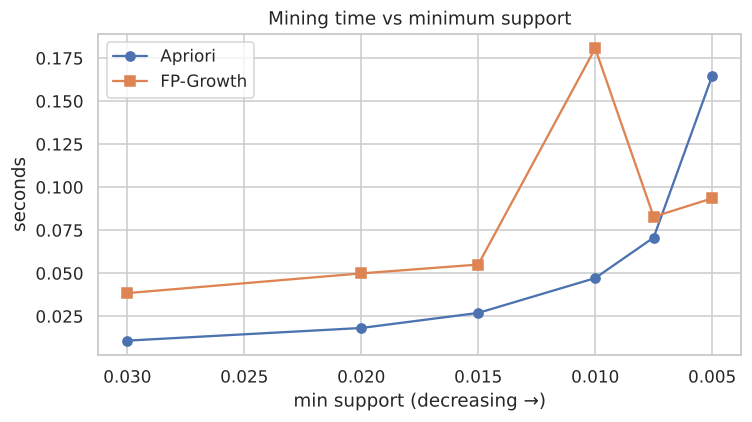

,min_support,itemsets,apriori_s,fpgrowth_s
0,0.0300,66,0.0108,0.0384
1,0.0200,120,0.0182,0.0499
2,0.0150,174,0.0269,0.0550
3,0.0100,322,0.0472,0.1807
4,0.0075,510,0.0707,0.0828
5,0.0050,959,0.1646,0.0935


In [9]:
# Runtime scaling across support thresholds
rows = []
for s in [0.03, 0.02, 0.015, 0.01, 0.0075, 0.005]:
    t0 = time.perf_counter(); a = apriori(disc_r, min_support=s, use_colnames=True); ta = time.perf_counter() - t0
    t0 = time.perf_counter(); f = fpgrowth(disc_r, min_support=s, use_colnames=True); tf = time.perf_counter() - t0
    rows.append((s, len(a), ta, tf))
rt = pd.DataFrame(rows, columns=["min_support", "itemsets", "apriori_s", "fpgrowth_s"])
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(rt.min_support, rt.apriori_s, "o-", label="Apriori"); ax.plot(rt.min_support, rt.fpgrowth_s, "s-", label="FP-Growth")
ax.invert_xaxis(); ax.set(title="Mining time vs minimum support", xlabel="min support (decreasing →)", ylabel="seconds"); ax.legend()
plt.tight_layout(); plt.savefig("figures/02_runtime.png"); plt.show()
rt.round(4)

In [10]:
rules = association_rules(fi_fp, metric="lift", min_threshold=1.0)
rules = rules[["antecedents", "consequents", "antecedent support", "consequent support", "support", "confidence", "lift", "leverage", "conviction"]]
print(f"Item-level rules with lift > 1: {len(rules)}")
rules.sort_values("lift", ascending=False).head(10).round(3)

Item-level rules with lift > 1: 592


,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,leverage,conviction
351,frozenset({root vegetables}),"frozenset({citrus fruit, other vegetables})",0.106,0.028,0.011,0.105,3.671,0.008,1.085
350,"frozenset({citrus fruit, other vegetables})",frozenset({root vegetables}),0.028,0.106,0.011,0.390,3.671,0.008,1.465
348,"frozenset({root vegetables, citrus fruit})",frozenset({other vegetables}),0.018,0.195,0.011,0.626,3.215,0.008,2.153
353,frozenset({other vegetables}),"frozenset({root vegetables, citrus fruit})",0.195,0.018,0.011,0.057,3.215,0.008,1.042
193,"frozenset({tropical fruit, other vegetables})",frozenset({root vegetables}),0.035,0.106,0.012,0.337,3.171,0.008,1.348
196,frozenset({root vegetables}),"frozenset({tropical fruit, other vegetables})",0.106,0.035,0.012,0.112,3.171,0.008,1.086
560,frozenset({beef}),frozenset({root vegetables}),0.052,0.106,0.017,0.324,3.052,0.011,1.323
561,frozenset({root vegetables}),frozenset({beef}),0.106,0.052,0.017,0.160,3.052,0.011,1.128
262,frozenset({butter}),frozenset({domestic eggs}),0.055,0.063,0.010,0.185,2.940,0.007,1.150
263,frozenset({domestic eggs}),frozenset({butter}),0.063,0.055,0.010,0.163,2.940,0.007,1.128


In [11]:
# Multi-level mining: department pairs (max_len=2 keeps the result readable for layout decisions)
fi_d = fpgrowth(disc_dept.drop(columns=["other"], errors="ignore"), min_support=0.05, use_colnames=True, max_len=2)
rules_d = association_rules(fi_d, metric="lift", min_threshold=1.0).sort_values("lift", ascending=False)
rules_d["pair"] = rules_d.apply(lambda r: f"{list(r.antecedents)[0]} → {list(r.consequents)[0]}", axis=1)
print(f"Department-pair rules with lift > 1: {len(rules_d)}")
TOP_DEPT_PAIR = rules_d.iloc[0]["pair"]
rules_d[["pair", "support", "confidence", "lift"]].head(10).round(3)

Department-pair rules with lift > 1: 44


,pair,support,confidence,lift
28,household & care → pantry,0.092,0.358,1.525
29,pantry → household & care,0.092,0.393,1.525
26,meat & fish → pantry,0.116,0.351,1.496
27,pantry → meat & fish,0.116,0.492,1.496
23,pantry → produce,0.158,0.674,1.431
22,produce → pantry,0.158,0.336,1.431
21,pantry → dairy,0.165,0.704,1.411
20,dairy → pantry,0.165,0.331,1.411
30,meat & fish → produce,0.211,0.642,1.363
31,produce → meat & fish,0.211,0.448,1.363


---
# Step 5 — Interpretation / Evaluation

## 5.1 Interestingness measures
- **Confidence** is biased toward frequent consequents: *{anything} → {whole milk}* has high confidence just because milk is in 25% of baskets.
- **Lift** corrects for this (>1 = positive association); **leverage** gives the absolute excess co-occurrence; **conviction** captures directionality.

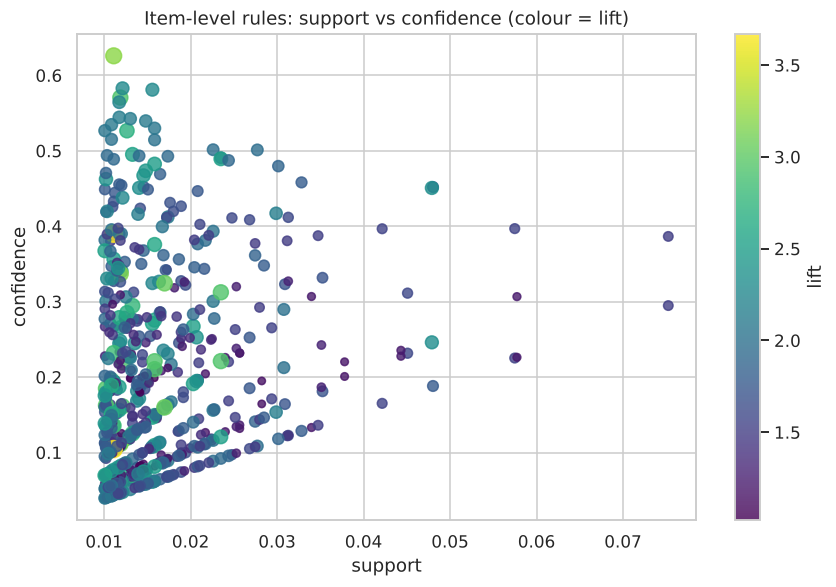

In [12]:
fig, ax = plt.subplots(figsize=(8, 5.5))
sc = ax.scatter(rules.support, rules.confidence, c=rules.lift, cmap="viridis", s=18 + 40 * (rules.lift - 1), alpha=.8)
plt.colorbar(sc, label="lift"); ax.set(title="Item-level rules: support vs confidence (colour = lift)", xlabel="support", ylabel="confidence")
plt.tight_layout(); plt.savefig("figures/03_rules_scatter.png"); plt.show()

## 5.2 Statistical validity — Fisher's exact test with Bonferroni correction
With hundreds of candidate rules, some will look interesting purely by chance. Each rule's 2×2 contingency table is tested and the significance level divided by the number of rules tested.

In [13]:
N = len(disc_r)
def fisher_p(r):
    a_sup, c_sup, s = r["antecedent support"], r["consequent support"], r["support"]
    n11 = round(s * N); n10 = round(a_sup * N) - n11; n01 = round(c_sup * N) - n11; n00 = N - n11 - n10 - n01
    return fisher_exact([[n11, n10], [n01, n00]], alternative="greater")[1]
rules["p_value"] = rules.apply(fisher_p, axis=1)
alpha = 0.05 / len(rules)
rules["significant"] = rules.p_value < alpha
print(f"Bonferroni α = {alpha:.2e}  →  significant rules: {rules.significant.sum()} of {len(rules)}")

Bonferroni α = 8.45e-05  →  significant rules: 468 of 592


## 5.3 Redundancy pruning
A rule *{A, B} → C* is redundant if a simpler rule *{A} → C* (or *{B} → C*) already has equal or higher confidence: the extra item adds no knowledge.

In [14]:
sig = rules[rules.significant].copy()
best_conf = {(frozenset(r.antecedents), frozenset(r.consequents)): r.confidence for r in sig.itertuples()}
def redundant(r):
    A, Cq = frozenset(r.antecedents), frozenset(r.consequents)
    if len(A) < 2: return False
    return any(best_conf.get((A - {a}, Cq), -1) >= r.confidence for a in A)
sig["redundant"] = sig.apply(redundant, axis=1)
pruned = sig[~sig.redundant]
print(f"Significant rules: {len(sig)} → after redundancy pruning: {len(pruned)}")

Significant rules: 468 → after redundancy pruning: 466


## 5.4 Hold-out validation (is the knowledge *valid* on new data?)
Recompute each rule's support, confidence and lift on the 20% hold-out baskets that were never used for mining.

Rules whose lift stays > 1 on hold-out: 454 of 466 (97%)
Correlation of lift (discovery vs hold-out): 0.63


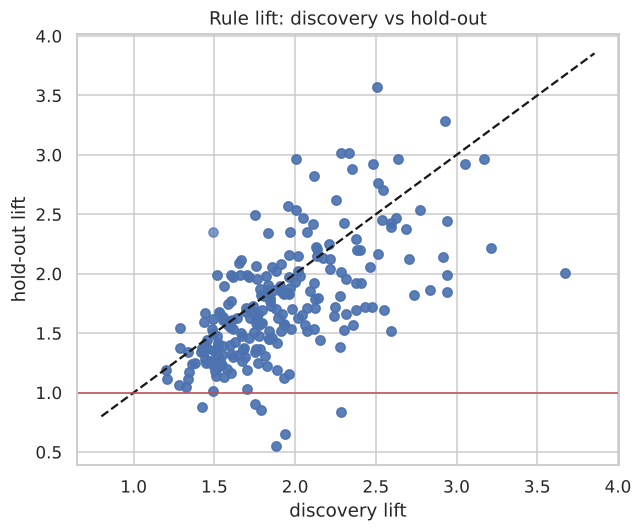

In [15]:
def metrics_on(df_bool, A, Cq):
    a = df_bool[list(A)].all(axis=1); c = df_bool[list(Cq)].all(axis=1)
    sup_a, sup_c, sup_ac = a.mean(), c.mean(), (a & c).mean()
    conf = sup_ac / sup_a if sup_a else np.nan
    return pd.Series({"hold_support": sup_ac, "hold_confidence": conf, "hold_lift": conf / sup_c if sup_c else np.nan})
val = pruned.apply(lambda r: metrics_on(hold_r, r.antecedents, r.consequents), axis=1)
validated = pd.concat([pruned, val], axis=1)
validated["stable"] = validated.hold_lift > 1.0
print(f"Rules whose lift stays > 1 on hold-out: {validated.stable.sum()} of {len(validated)} ({validated.stable.mean():.0%})")
print(f"Correlation of lift (discovery vs hold-out): {validated[['lift','hold_lift']].corr().iloc[0,1]:.2f}")
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(validated.lift, validated.hold_lift, alpha=.7); lim = [0.8, validated[["lift", "hold_lift"]].max().max() * 1.05]
ax.plot(lim, lim, "k--"); ax.axhline(1, c="r", lw=1)
ax.set(title="Rule lift: discovery vs hold-out", xlabel="discovery lift", ylabel="hold-out lift")
plt.tight_layout(); plt.savefig("figures/04_holdout_lift.png"); plt.show()

### KDD iteration — going back a step
A first pass (min-support 1%, no confidence filter) produced many rules whose consequent is *whole milk* or *other vegetables* — valid but obvious (prior knowledge from Step 0). Following the iterative nature of KDD, the evaluation criteria are tightened to surface **novel** knowledge: keep rules that are significant, non-redundant, stable on hold-out, with confidence ≥ 0.3 and lift ≥ 1.5 — and look separately at rules **not** ending in the two mega-staples.

In [16]:
STAPLES = {"whole milk", "other vegetables"}
final = validated[validated.stable & (validated.confidence >= 0.30) & (validated.lift >= 1.5)].copy()
final["rule"] = final.apply(lambda r: f"{{{', '.join(sorted(r.antecedents))}}} → {{{', '.join(sorted(r.consequents))}}}", axis=1)
final["novel"] = ~final.consequents.apply(lambda c: set(c) <= STAPLES)
cols = ["rule", "support", "confidence", "lift", "hold_lift", "conviction", "p_value"]
print(f"Final knowledge base: {len(final)} rules ({final.novel.sum()} with non-staple consequents)")
print("\nTop non-staple ('novel') rules:")
display(final[final.novel].sort_values("lift", ascending=False)[cols].head(12).round(4))
print("Top rules overall:")
final.sort_values("lift", ascending=False)[cols].head(8).round(4)

Final knowledge base: 112 rules (18 with non-staple consequents)

Top non-staple ('novel') rules:


,rule,support,confidence,lift,hold_lift,conviction,p_value
350,"{citrus fruit, other vegetables} → {root vegetables}",0.0111,0.3901,3.6711,2.0061,1.4655,0.0
193,"{other vegetables, tropical fruit} → {root vegetables}",0.0119,0.3370,3.1707,2.9667,1.3479,0.0
560,{beef} → {root vegetables},0.0170,0.3244,3.0525,2.9247,1.3228,0.0
176,"{other vegetables, whole milk} → {root vegetables}",0.0235,0.3124,2.9396,2.4420,1.2998,0.0
61,"{tropical fruit, whole milk} → {yogurt}",0.0158,0.3758,2.5942,2.3915,1.3699,0.0
555,"{fruit/vegetable juice, whole milk} → {yogurt}",0.0101,0.3674,2.5368,2.4506,1.3519,0.0
344,"{citrus fruit, whole milk} → {yogurt}",0.0111,0.3566,2.4616,2.0567,1.3290,0.0
527,{berries} → {yogurt},0.0116,0.3447,2.3797,1.6976,1.3050,0.0
67,"{other vegetables, tropical fruit} → {yogurt}",0.0120,0.3406,2.3513,2.8848,1.2968,0.0
517,"{whipped/sour cream, whole milk} → {yogurt}",0.0109,0.3307,2.2834,3.0165,1.2778,0.0


Top rules overall:


,rule,support,confidence,lift,hold_lift,conviction,p_value
350,"{citrus fruit, other vegetables} → {root vegetables}",0.0111,0.3901,3.6711,2.0061,1.4655,0.0
348,"{citrus fruit, root vegetables} → {other vegetables}",0.0111,0.6259,3.2153,2.2141,2.1527,0.0
193,"{other vegetables, tropical fruit} → {root vegetables}",0.0119,0.3370,3.1707,2.9667,1.3479,0.0
560,{beef} → {root vegetables},0.0170,0.3244,3.0525,2.9247,1.3228,0.0
176,"{other vegetables, whole milk} → {root vegetables}",0.0235,0.3124,2.9396,2.4420,1.2998,0.0
192,"{root vegetables, tropical fruit} → {other vegetables}",0.0119,0.5706,2.9310,3.2876,1.8753,0.0
180,"{rolls/buns, root vegetables} → {other vegetables}",0.0126,0.5266,2.7052,2.1273,1.7012,0.0
61,"{tropical fruit, whole milk} → {yogurt}",0.0158,0.3758,2.5942,2.3915,1.3699,0.0


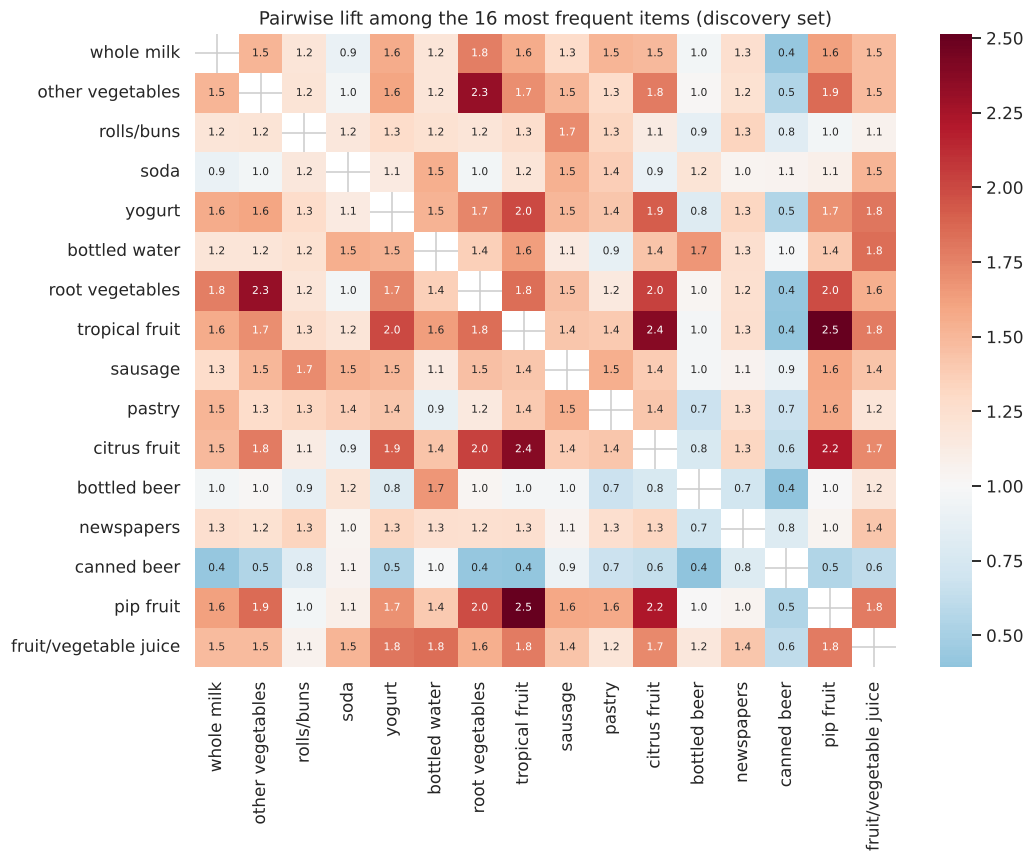

In [17]:
top_items = list(support[keep].sort_values(ascending=False).head(16).index)
lift_m = pd.DataFrame(index=top_items, columns=top_items, dtype=float)
for a in top_items:
    for b in top_items:
        if a != b:
            pa, pb, pab = disc[a].mean(), disc[b].mean(), (disc[a] & disc[b]).mean()
            lift_m.loc[a, b] = pab / (pa * pb)
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(lift_m, cmap="RdBu_r", center=1, annot=True, fmt=".1f", annot_kws={"size": 7}, ax=ax)
ax.set_title("Pairwise lift among the 16 most frequent items (discovery set)")
plt.tight_layout(); plt.savefig("figures/05_lift_heatmap.png"); plt.show()

## 5.5 Knowledge consolidation
Interpreting the validated rules in domain terms:

| Discovered pattern | Interpretation | Possible action |
|---|---|---|
| Root vegetables / tropical fruit / citrus → other vegetables, yogurt | "fresh-produce shoppers" — health-oriented baskets | co-locate produce and chilled dairy; bundle fruit + yogurt |
| Curd, berries, whipped/sour cream, fruit + milk → yogurt | dairy & fresh fruit are shopped as one "chilled/fresh" mission | keep yogurt adjacent to fruit and other dairy; yogurt promotions for fruit buyers |
| Beef / pork / hamburger meat → root vegetables / other vegetables | "cooking a meal" mission | recipe displays (meat + vegetables) near the butcher counter |
| Department-pair rules (Step 4 table) | which departments are shopped together beyond chance | adjacency / cross-merchandising for the highest-lift department pairs |

**Novelty check:** the rules that point to *non-staple* consequents (e.g. towards yogurt, root vegetables, rolls) are the most useful for recommendations, because recommending milk to someone who already buys it adds little value.

---
# Using the discovered knowledge
KDD ends with *acting on* the knowledge. The validated rule base is exported as JSON and wrapped in a simple recommender used by `app/streamlit_app.py`.

In [18]:
kb = [{"antecedents": sorted(r.antecedents), "consequents": sorted(r.consequents), "support": round(r.support, 4),
       "confidence": round(r.confidence, 4), "lift": round(r.lift, 3), "holdout_lift": round(r.hold_lift, 3)}
      for r in final.itertuples()]
json.dump(kb, open("models/rules.json", "w"), indent=2)

def recommend(basket, k=5, kb=kb):
    basket = set(basket); scores = {}
    for r in kb:
        if set(r["antecedents"]) <= basket:
            for c in r["consequents"]:
                if c not in basket:
                    scores[c] = max(scores.get(c, 0), r["confidence"] * r["lift"])
    return sorted(scores.items(), key=lambda x: -x[1])[:k]

for b in [["root vegetables", "beef"], ["yogurt", "tropical fruit"], ["curd"]]:
    print(b, "→", [(i, round(s, 2)) for i, s in recommend(b)])

['root vegetables', 'beef'] → [('other vegetables', 1.04), ('whole milk', 0.8)]
['yogurt', 'tropical fruit'] → [('whole milk', 1.04), ('other vegetables', 0.78)]
['curd'] → [('whole milk', 0.93), ('yogurt', 0.74), ('other vegetables', 0.6)]


In [19]:
# Offline evaluation of the recommender on hold-out baskets: hide one item, see if it is recommended (hit-rate@5)
hits = trials = pop_hits = hyb_hits = 0
rng2 = np.random.default_rng(1)
pop_order = list(support.sort_values(ascending=False).index)
for b in hold_b:
    if len(b) < 2: continue
    hidden = b[rng2.integers(len(b))]; rest = [i for i in b if i != hidden]
    recs = [i for i, _ in recommend(rest, 5)]
    if recs:
        trials += 1; hits += hidden in recs
        pop5 = [i for i in pop_order if i not in rest][:5]   # baseline: 5 most popular items not already in basket
        pop_hits += hidden in pop5
        hybrid = (recs + [i for i in pop5 if i not in recs])[:5]   # rules first, popularity fills empty slots
        hyb_hits += hidden in hybrid
print(f"Baskets where a rule fired: {trials}")
print(f"Rule recommender hit-rate@5 : {hits/trials:.1%}")
print(f"Popularity baseline hit-rate@5: {pop_hits/trials:.1%}")
print(f"Hybrid (rules + popularity fill) hit-rate@5: {hyb_hits/trials:.1%}")
print(f"Avg. number of rule-based recommendations per basket: {np.mean([len(recommend([i for i in b][:-1], 5)) for b in hold_b if len(b) > 1]):.2f}")
summary = {"transactions": len(raw_baskets), "after_preprocessing": len(pre), "items": int(len(item_freq)),
           "items_after_reduction": int(len(keep)), "frequent_itemsets": int(len(fi_fp)), "apriori_ms": round(t_ap*1000, 1),
           "fpgrowth_ms": round(t_fp*1000, 1), "rules_lift_gt1": int(len(rules)), "significant": int(rules.significant.sum()),
           "non_redundant": int(len(pruned)), "stable_holdout": int(validated.stable.sum()), "final_rules": int(len(final)),
           "novel_rules": int(final.novel.sum()), "hit_rate_at5": round(hits / trials, 4), "popularity_hit_rate_at5": round(pop_hits / trials, 4), "hybrid_hit_rate_at5": round(hyb_hits / trials, 4), "rec_trials": trials}
json.dump(summary, open("models/kdd_summary.json", "w"), indent=2); summary

Baskets where a rule fired: 1151
Rule recommender hit-rate@5 : 14.9%
Popularity baseline hit-rate@5: 27.2%
Hybrid (rules + popularity fill) hit-rate@5: 27.6%
Avg. number of rule-based recommendations per basket: 1.51


{'transactions': 9835,
 'after_preprocessing': 9787,
 'items': 169,
 'items_after_reduction': 119,
 'frequent_itemsets': 322,
 'apriori_ms': 88.5,
 'fpgrowth_ms': 77.4,
 'rules_lift_gt1': 592,
 'significant': 468,
 'non_redundant': 466,
 'stable_holdout': 454,
 'final_rules': 112,
 'novel_rules': 18,
 'hit_rate_at5': 0.1494,
 'popularity_hit_rate_at5': 0.2719,
 'hybrid_hit_rate_at5': 0.2763,
 'rec_trials': 1151}

**Evaluation finding (honest):** rules alone usually propose fewer than 5 items, so their raw hit-rate is below a popularity baseline — rules are *precise but sparse*. The knowledge is most useful as a **re-ranking layer on top of popularity** (hybrid), and for merchandising decisions rather than as a stand-alone recommender. This is exactly the "is the pattern useful?" question KDD asks in its final step.

## Reflection — what makes this KDD rather than CRISP-DM or SEMMA?
- The goal is **discovery of understandable knowledge**, not a predictive model with a business KPI — there is no target variable.
- **Transformation** is a first-class step: the concept hierarchy (item → department) created a new *view* of the data that produced different, layout-level knowledge.
- **Interpretation/Evaluation** asks "is this pattern valid, novel, useful, understandable?" — answered here with significance testing, hold-out stability, redundancy pruning and a novelty filter, and it **looped back** to tighten the mining criteria.